# Comparison of two groups using Cox regression

The comparison of the previous notebook, now with `lifelines`: first the log-rank, Wilcoxon and Peto-Peto tests, and then a Cox regression model whose only variable is the group. The Cox model does not only test the difference, it also measures it, with the hazard ratio.

The data are the survival times, in months, of 45 women with breast cancer, whose tumours were negatively (`stain` 1) or positively (`stain` 2) stained.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test

In [2]:
# Colors shared by all the plots
GROUP_COLORS = {'Stain Negative': '#1f4e79', 'Stain Positive': '#E69F00'}
point_color = '#c1121f'
line_color  = '#1f4e79'
ref_color   = '#333333'

## The data

In [3]:
DatOriginal = pd.read_csv("data/breast_cancer_prognosis.dat", sep=r"\s+")

In [4]:
DatOriginal.head()

,stain,time,status
0,1,23,1
1,1,47,1
2,1,69,1
3,1,70,0
4,1,71,0


In [5]:
DatOriginalNegative = DatOriginal[DatOriginal['stain']==1]
DatOriginalPositive = DatOriginal[DatOriginal['stain']==2]

## Survivor function for each group

In [6]:
def PlotKm(ax, kmf, color, band=True):
    # Kaplan-Meier estimator as a step function, with a tick at each censored time
    surv = kmf.survival_function_.iloc[:, 0]
    if band:
        ci = kmf.confidence_interval_
        ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], step='post', color=color, alpha=0.25, lw=0)
    ax.step(surv.index, surv, where='post', color=color, lw=2, label=surv.name)
    censored = kmf.event_table.index[kmf.event_table['censored'] > 0]
    ax.plot(censored, surv.loc[censored], '|', color=color, markersize=11, markeredgewidth=2)

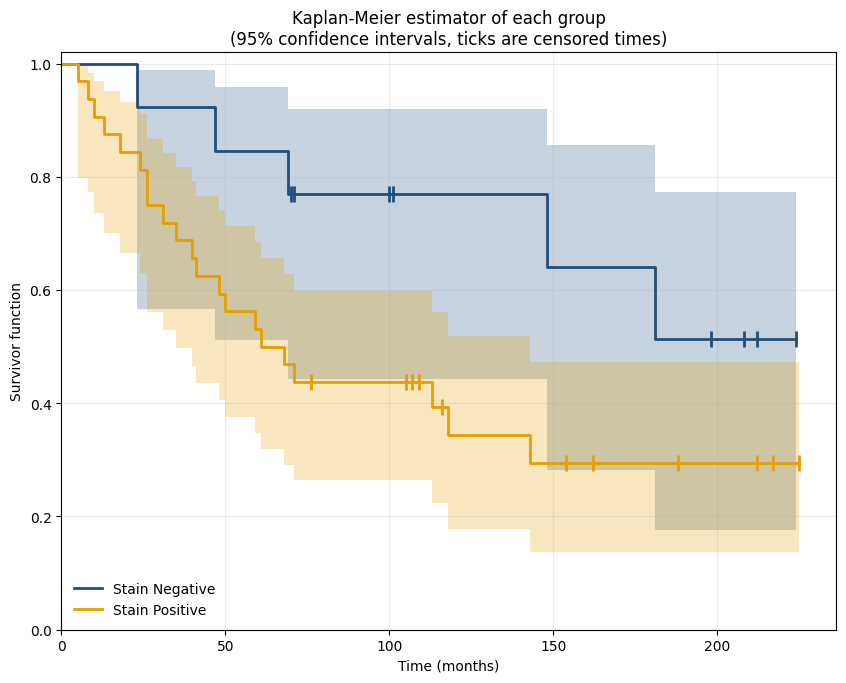

In [7]:
kmfNegative = KaplanMeierFitter()
kmfNegative.fit(DatOriginalNegative['time'], event_observed=DatOriginalNegative['status'], label="Stain Negative")

kmfPositive = KaplanMeierFitter()
kmfPositive.fit(DatOriginalPositive['time'], event_observed=DatOriginalPositive['status'], label="Stain Positive")

fig, ax = plt.subplots(figsize=(10, 7.5))
PlotKm(ax, kmfNegative, GROUP_COLORS['Stain Negative'])
PlotKm(ax, kmfPositive, GROUP_COLORS['Stain Positive'])

ax.set_xlabel('Time (months)')
ax.set_ylabel('Survivor function')
ax.set_xlim(0, None)
ax.set_ylim(0, 1.02)
ax.set_title('Kaplan-Meier estimator of each group\n(95% confidence intervals, ticks are censored times)')
ax.legend(loc='lower left', frameon=False)
ax.grid(True, alpha=0.25)

## Hypothesis test of equal survivor function

In [8]:
logrank_test(
    DatOriginalNegative['time'],
    DatOriginalPositive['time'],
    DatOriginalNegative['status'],
    DatOriginalPositive['status']
)

<lifelines.StatisticalResult: logrank_test>
               t_0 = -1
 null_distribution = chi squared
degrees_of_freedom = 1
         test_name = logrank_test

---
 test_statistic    p  -log2(p)
           3.51 0.06      4.04

In [9]:
logrank_test(
    DatOriginalNegative['time'],
    DatOriginalPositive['time'],
    DatOriginalNegative['status'],
    DatOriginalPositive['status'],
    weightings='wilcoxon'
)

<lifelines.StatisticalResult: Wilcoxon_test>
               t_0 = -1
 null_distribution = chi squared
degrees_of_freedom = 1
         test_name = Wilcoxon_test

---
 test_statistic    p  -log2(p)
           4.18 0.04      4.61

In [10]:
logrank_test(
    DatOriginalNegative['time'],
    DatOriginalPositive['time'],
    DatOriginalNegative['status'],
    DatOriginalPositive['status'],
    weightings='peto'
)

<lifelines.StatisticalResult: Peto_test>
               t_0 = -1
 null_distribution = chi squared
degrees_of_freedom = 1
         test_name = Peto_test

---
 test_statistic    p  -log2(p)
           4.12 0.04      4.56

## Using Cox regression

According to ```lifelines```: There are only disadvantages to using the log-rank test versus using the Cox regression. To convert to using the Cox regression:

In [11]:
cph = CoxPHFitter()
cph.fit(DatOriginal, 'time', 'status', formula='C(stain)')
cph.print_summary()

<lifelines.CoxPHFitter: fitted with 45 total observations, 19 right-censored observations>
             duration col = 'time'
                event col = 'status'
      baseline estimation = breslow
   number of observations = 45
number of events observed = 26
   partial log-likelihood = -85.01
         time fit was run = 2026-10-13 02:57:07 UTC

---
               coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                      
C(stain)[T.2]  0.91      2.48      0.50           -0.07            1.89                0.93                6.63

               cmp to    z    p  -log2(p)
covariate                                
C(stain)[T.2]    0.00 1.82 0.07      3.85
---
Concordance = 0.60
Partial AIC = 172.03
log-likelihood ratio test = 3.88 on 1 df
-log2(p) of ll-ratio test = 4.36

The estimated coefficient with its confidence interval, and the same in the scale of the hazard ratio.

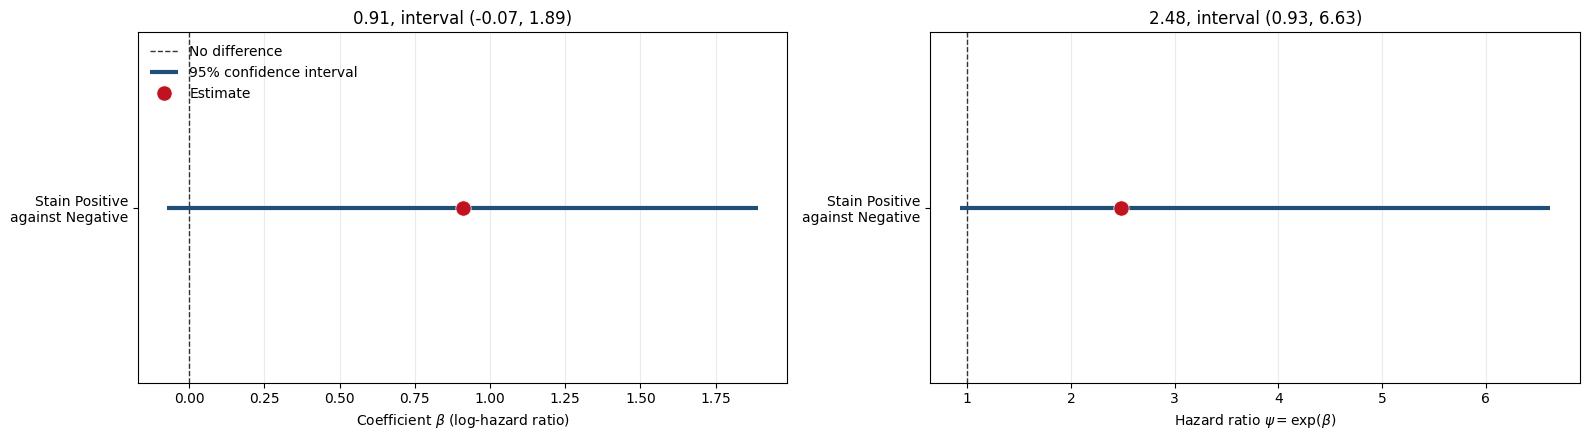

In [12]:
Summary = cph.summary.iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
panels = [('coef', 'coef lower 95%', 'coef upper 95%', 0, r'Coefficient $\beta$ (log-hazard ratio)'),
          ('exp(coef)', 'exp(coef) lower 95%', 'exp(coef) upper 95%', 1, r'Hazard ratio $\psi=\exp(\beta)$')]
for ax, (estimate, lower, upper, reference, label) in zip(axes, panels):
    ax.axvline(reference, color=ref_color, lw=1, ls='--', label='No difference')
    ax.plot([Summary[lower], Summary[upper]], [0, 0], color=line_color, lw=3, solid_capstyle='butt',
            label='95% confidence interval')
    ax.plot(Summary[estimate], 0, 'o', color=point_color, markersize=11, markeredgecolor='white', markeredgewidth=0.5,
            label='Estimate')
    ax.set_yticks([0], ['Stain Positive\nagainst Negative'])
    ax.set_ylim(-1, 1)
    ax.set_xlabel(label)
    ax.set_title(f'{Summary[estimate]:.2f}, interval ({Summary[lower]:.2f}, {Summary[upper]:.2f})')
    ax.grid(True, axis='x', alpha=0.25)
axes[0].legend(loc='upper left', frameon=False)
plt.tight_layout()

The hazard ratio is given by $$\psi=\exp(\beta).$$ We can conclude that a woman whose tumour was positively stained has around 2.48 times the risk of dying at any given time.

Furthermore, the $P$-value for the hypothesis that $\beta=0$ is 0.07, which can be translated as slight evidence against the hypothesis of equal hazard

In [13]:
ZStatistic = cph.summary['coef'] / cph.summary['se(coef)']
ZStatistic

covariate
C(stain)[T.2]    1.815288
dtype: float64

In [14]:
PValue = 2*norm.sf(np.abs(ZStatistic))
PValue

array([0.06947962])

$-2\log$-likelihood statistic

In [15]:
-2*cph.log_likelihood_

np.float64(170.02995571337104)

The log-likelihood ratio test allows us to compare the model against the null model, which has no covariates.

The test statistic is $$-2\log\text{-likelihood}_{\text{Null}}+2\log\text{-likelihood}_{\text{Model}}$$

In [16]:
cph.log_likelihood_ratio_test()

<lifelines.StatisticalResult: log-likelihood ratio test>
null_distribution = chi squared
  degrees_freedom = 1
        test_name = log-likelihood ratio test

---
 test_statistic    p  -log2(p)
           3.88 0.05      4.36

We can conclude that there is slight evidence that the hazard functions for the two groups of women are different.

## The survivor functions of the Cox model

In the Cox model the hazards of the two groups are proportional, so one survivor function is a power of the other: $S_{\text{Positive}}(t)=S_{\text{Negative}}(t)^\psi$. The curves of the model follow the Kaplan-Meier estimators.

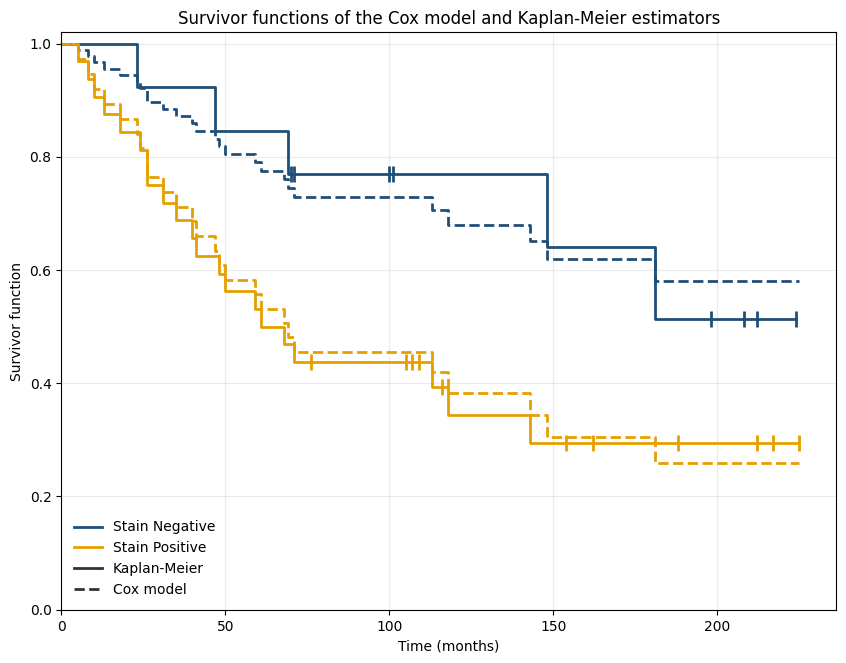

In [17]:
SurvivorCox = cph.predict_survival_function(pd.DataFrame({'stain': [1, 2]}))

fig, ax = plt.subplots(figsize=(10, 7.5))
PlotKm(ax, kmfNegative, GROUP_COLORS['Stain Negative'], band=False)
PlotKm(ax, kmfPositive, GROUP_COLORS['Stain Positive'], band=False)
for column, color in zip(SurvivorCox.columns, GROUP_COLORS.values()):
    ax.step(np.append(0, SurvivorCox.index), np.append(1, SurvivorCox[column]), where='post', color=color, lw=2, ls='--')
ax.plot([], [], color=ref_color, lw=2, label='Kaplan-Meier')
ax.plot([], [], color=ref_color, lw=2, ls='--', label='Cox model')

ax.set_xlabel('Time (months)')
ax.set_ylabel('Survivor function')
ax.set_xlim(0, None)
ax.set_ylim(0, 1.02)
ax.set_title('Survivor functions of the Cox model and Kaplan-Meier estimators')
ax.legend(loc='lower left', frameon=False)
ax.grid(True, alpha=0.25)